# Equity Return Predictability — Lecture Replication and Post-2011 Downturn Analysis

**Economic question:** Are post-2011 equity returns more predictable during economic downturns than during normal market conditions?

**Audience:** Pension-fund managers and long-horizon institutional investors.

**Research design:** Four forward excess-return horizons (3, 12, 24, and 60 months), 14 lecture predictors, overlap-robust HAC inference, pre/post-2012 comparisons, a full-history NBER recession interaction (primary historical test), and a separate post-2011 VIX stress interaction (supplementary test). All outputs are generated from the included data. Observational predictive associations are not causal evidence or a market-timing strategy.

### Reproducibility

**How to read the replication:** The lecture's table *layout, predictor set, four horizons, correlations, and t-statistics* are the targets. Numerical estimates are **not required to match** because the sample has been extended and some definitions/proxies differ. The lecture benchmark, extended-sample result, and pre-2012 result are separated so differences are visible.

**Interpretation boundaries:** Future excess returns are calculated as compounded CRSP dividend-inclusive total returns minus compounded approximate Treasury-bill returns. Valuation ratios are based on CRSP–Compustat matched firms with a six-month annual-accounting availability lag, rather than a published market-wide valuation index. Quarterly CAY is carried forward only within its available historical coverage, with a conservative availability lag. NBER recession interactions use the historical sample; post-2011 high-VIX conditions are a *supplementary* stress definition, not an NBER-recession replacement. The post-2011 NBER recession subsample is too small for a reliable separate recession regression. GARCH parameters are trained before 2012 and evaluated on later next-month returns; the model is fixed rather than periodically re-estimated.


## 1. Economic question and intended audience

The question and audience are stated above. The hypothesis is that recession-state information may alter the forecasting relationship between current valuation or macro-financial variables and future total equity returns.

## 2. Data sources and predictor construction

**Sources:** CRSP monthly value- and equal-weighted total return indexes; annual Compustat accounting data linked by dated CCM identifiers; FRED macroeconomic and financial series. `Dividend_yield` and `Earnings_yield` are constructed from aggregated accounting dividends/earnings divided by fiscal-year market capitalization, with six-month publication lag. This is a **cohort-based approximation** and does not exactly reproduce market-level dividend/earnings yields. Daily VIX, Treasury term spread and BAA spread are monthly averaged; daily oil is last observed price; CPI and industrial production use year-over-year log growth; GDP is year-over-year quarterly log growth released with a conservative three-month lag. FRED monthly predictors are shifted one month. `BAA10Y` is BAA corporate yield less the 10-year Treasury yield, **not** the slide’s BAA–AAA spread. The lecture’s consumption–wealth ratio and past-quarter volatility are not in the supplied data and are benchmark-only rows. See the code below for precise definitions.

**Credit spread correction:** Moody’s Baa minus Aaa yields (`BAA - AAA`), using the newly provided FRED CSVs, replaces `BAA10Y` (Baa minus Treasury).

**Consumption–wealth ratio (cay):** Authors' historical quarterly series: [Martin Lettau research data](https://sites.google.com/view/martinlettau/data), current posted coverage **1951Q2–2019Q3**. The original data must be added to `data/cay_current.csv` with standardized columns `quarter,cay` (e.g. `1951Q2,0.01`). It is deliberately not extrapolated through 2025. The published historical series is a *revised-vintage* series, not a real-time point-in-time predictor.

**Valuation caveat:** The present fiscal-cohort Compustat aggregation remains an approximation; do not describe it as monthly CRSP capitalization-matched market yields. Rebuilding it requires historical security classifications, PERMNO-month market caps, and point-in-time firm matching.

**Valuation improvement:** Individual-security monthly CRSP capitalization is linked through valid dated CCM identifiers to lagged annual Compustat earnings/dividends. Monthly aggregate ratios are calculated for the *matched investable coverage universe*, not the whole market; the eligible security universe and numerator/denominator are kept consistent. CRSP `MthCap` is in thousands of USD; Compustat accounting items are in millions. The reporting-availability assumption is fiscal-year end + six months. This remains an approximation to point-in-time announcement data.

**Credit spread:** Moody's Baa corporate yield minus Moody's Aaa corporate yield, not BAA10Y.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display
DATA=Path('data')  # All computed tables and figures display inline; no output files are written.
HORIZONS={'1 quarter':3,'1 year':12,'2 years':24,'5 years':60}
print('pandas',pd.__version__,'statsmodels',sm.__version__)

pandas 2.2.3 statsmodels 0.14.6


In [2]:
audit=[]
def log(stage, before, after, note=''):
    audit.append(dict(stage=stage,before=int(before),after=int(after),affected=int(before-after),note=note))
idx=pd.read_csv(DATA/'crsp_index.csv');idx.columns=idx.columns.str.lower()
idx['date']=pd.to_datetime(idx['mthcaldt']).dt.to_period('M').dt.to_timestamp('M')
log('Index duplicate dates',len(idx),len(idx.drop_duplicates('date')))
idx=idx.drop_duplicates('date').sort_values('date').set_index('date')
for c in ['vwretd','ewretd','vwretx'] :idx[c]=pd.to_numeric(idx[c],errors='coerce')
log('Index valid total returns',len(idx),idx.vwretd.notna().sum())
assert idx.index.is_unique and (idx.vwretd.dropna()>-1).all()
print(idx[['vwretd','ewretd']].agg(['count','min','max']))

            vwretd       ewretd
count  1200.000000  1200.000000
min      -0.291731    -0.312753
max       0.394144     0.668097


In [3]:
def fred(name):
    f=pd.read_csv(DATA/f'{name}.csv');f.columns=['date',name]
    f['date']=pd.to_datetime(f.date);f[name]=pd.to_numeric(f[name],errors='coerce')
    return f.set_index('date')[name].sort_index()
macro=pd.DataFrame(index=idx.index)
for c in ['T10Y3M','VIXCLS']:
    macro[c]=fred(c).resample('ME').mean().reindex(idx.index)
macro['oil']=fred('DCOILWTICO').resample('ME').last().reindex(idx.index)
for c in ['CPIAUCSL','INDPRO','UNRATE','TB3MS','USREC']:
    macro[c]=fred(c).resample('ME').last().reindex(idx.index)
gdp=fred('GDPC1').dropna(); gdp.index=gdp.index.to_period('Q').to_timestamp('Q')
gdp_growth=100*np.log(gdp/gdp.shift(4));gdp_growth.index=gdp_growth.index+pd.DateOffset(months=3)
macro['GDP_growth']=gdp_growth.reindex(idx.index,method='ffill')
macro['Inflation']=100*np.log(macro.CPIAUCSL/macro.CPIAUCSL.shift(12))
macro['IP_growth']=100*np.log(macro.INDPRO/macro.INDPRO.shift(12))
macro['Oil_growth']=100*np.log(macro.oil/macro.oil.shift(12))
macro['Term_spread']=macro.T10Y3M
macro['Credit_spread']=(fred('BAA')-fred('AAA')).resample('ME').last().reindex(idx.index) # Moody's Baa minus Aaa
macro['Unemployment']=macro.UNRATE
macro['VIX']=macro.VIXCLS
macro['Tbill']=macro.TB3MS
# 1-month conservative availability lag for ordinary macro predictors
predictor_macro=['Term_spread','Credit_spread','GDP_growth','Inflation','IP_growth','Oil_growth','Unemployment','VIX']
macro[predictor_macro]=macro[predictor_macro].shift(1)
print(macro[predictor_macro+['USREC']].count())

Term_spread       527
Credit_spread    1199
GDP_growth        930
Inflation         934
IP_growth        1187
Oil_growth        467
Unemployment      934
VIX               431
USREC            1200
dtype: int64


In [4]:
# Construct monthly matched-firm valuation ratios using the uploaded CRSP stock file.
# Accounting data are lagged six months to approximate public availability.
a=pd.read_csv(DATA/'compustat_annual.csv',parse_dates=['datadate'],low_memory=False)
links=pd.read_csv(DATA/'ccm_links.csv')
for c in ['LINKDT','LINKENDDT']: links[c]=pd.to_datetime(links[c],errors='coerce')
log('Annual duplicate gvkey-datadate',len(a),len(a.drop_duplicates(['gvkey','datadate'])))
a=a.drop_duplicates(['gvkey','datadate'])
a=a[(a.consol=='C')&(a.indfmt=='INDL')&(a.datafmt=='STD')&(a.curcd=='USD')].copy()
a['available']=(a.datadate+pd.DateOffset(months=6)).dt.to_period('M').dt.to_timestamp('M')
a=a[['gvkey','datadate','available','dvc','ib']].dropna(subset=['available']).copy()
links=links[links.LINKTYPE.isin(['LC','LU']) & links.LINKPRIM.isin(['P','C'])].copy()
links.LINKDT=links.LINKDT.fillna(pd.Timestamp('1900-01-01'))
links.LINKENDDT=links.LINKENDDT.fillna(pd.Timestamp('2100-01-01'))
links['LPERMNO']=pd.to_numeric(links.LPERMNO,errors='coerce')
stock=pd.read_csv(DATA/'crsp_stock_compact.csv',parse_dates=['MthCalDt'])
stock=stock.rename(columns={'PERMNO':'LPERMNO','MthCalDt':'date','MthCap':'market_cap_thousands'})
stock['date']=stock.date.dt.to_period('M').dt.to_timestamp('M')
stock=stock.dropna(subset=['LPERMNO','market_cap_thousands','date'])
stock=stock[stock.market_cap_thousands>0]
log('CRSP stock duplicate permno-month',len(stock),len(stock.drop_duplicates(['LPERMNO','date'])))
stock=stock.drop_duplicates(['LPERMNO','date'])
linked=stock.merge(links[['gvkey','LPERMNO','LINKDT','LINKENDDT','LINKPRIM']],on='LPERMNO',how='inner')
linked=linked[(linked.date>=linked.LINKDT)&(linked.date<=linked.LINKENDDT)].copy()
linked=linked.sort_values(['LPERMNO','date','LINKPRIM']).drop_duplicates(['LPERMNO','date'])
# Each firm-month gets the latest fiscal statement whose six-month availability lag has passed.
linked['gvkey']=linked.gvkey.astype(str);a['gvkey']=a.gvkey.astype(str)
linked=linked.sort_values(['date','gvkey']);a=a.sort_values(['available','gvkey'])
matched=pd.merge_asof(linked,a,left_on='date',right_on='available',by='gvkey',direction='backward',allow_exact_matches=True)
# Avoid stale fundamentals: annual data must be no older than 18 months after the assumed availability date.
matched=matched[(matched.available.notna())&((matched.date-matched.available).dt.days<=550)].copy()
# CRSP MthCap is thousands of dollars; convert to Compustat's millions.
matched['market_cap_millions']=matched.market_cap_thousands/1000
# Multiple eligible securities of the same issuer are consolidated at the firm-month level.
firm=matched.groupby(['date','gvkey'],as_index=False).agg(cap=('market_cap_millions','sum'),dvc=('dvc','first'),ib=('ib','first'))
# Earnings and dividend ratios use only matched firms with a nonmissing corresponding numerator.
records=[]
for date,g in firm.groupby('date'):
    rec={'date':date,'n_firms':g.gvkey.nunique()}
    for raw,target in [('dvc','Dividend_yield'),('ib','Earnings_yield')]:
        v=g[g[raw].notna() & (g.cap>0)]
        rec[target]=v[raw].sum()/v.cap.sum() if len(v)>0 else np.nan
        rec[f'{target}_firms']=len(v)
    records.append(rec)
val=pd.DataFrame(records).set_index('date').sort_index().reindex(idx.index)
print('Matched firm-months:',len(firm),'Valuation dates:',val.Dividend_yield.notna().sum())
display(val[['Dividend_yield','Earnings_yield','n_firms']].describe().round(3))

del stock,linked,matched,firm


Matched firm-months: 3294320 Valuation dates: 894


,Dividend_yield,Earnings_yield,n_firms
count,894.000,894.000,894.000
mean,0.027,0.058,3684.922
std,0.011,0.026,1960.279
min,0.009,0.005,12.000
25%,0.017,0.040,1966.750
50%,0.027,0.051,3895.000
75%,0.034,0.071,5015.250
max,0.057,0.140,7370.000


## 3. Dividend-inclusive excess-return construction

CRSP `vwretd` and `ewretd` include distributions. Future returns compound months **t+1 through t+h** (no contemporaneous return leakage). Excess holding-period return is compounded stock return **minus separately compounded risk-free return**, not a sum of monthly excess returns. `TB3MS` is an annualized three-month bill yield; conversion to a monthly effective rate is a documented *proxy*, not an observed one-month Treasury bill holding return. The same month-t risk-free rate is included as a predictor, but the forward benchmark uses months t+1 to t+h.


In [5]:
panel=idx[['vwretd','ewretd']].join(macro).join(val[['Dividend_yield','Earnings_yield']])
# TB3MS is annualized percent yield, not a realized one-month bill return.
# Monthly effective yield is an approximation; sensitivity should use actual one-month bills.
panel['rf_monthly']=(1+panel['TB3MS']/100)**(1/12)-1
panel['Past_quarter_volatility']=panel['vwretd'].rolling(3,min_periods=3).std()
panel['Past_1y_return']=(1+panel['vwretd']).rolling(12,min_periods=12).apply(np.prod,raw=True)-1
panel['Risk_free_rate']=panel['TB3MS']
PRED=['Dividend_yield','Earnings_yield']+predictor_macro+['Past_quarter_volatility','Past_1y_return','Risk_free_rate']
# Historical Lettau-Ludvigson cay is quarterly and available only through 2019Q3
# in the authors' posted current dataset. The series is NOT imputed after that date.
cay_file=DATA/'cay_current.csv'
if cay_file.exists():
    raw_cay=pd.read_csv(cay_file)
    print('CAY columns supplied:',raw_cay.columns.tolist())
    # Author file: date,c,w,y,cay=c-0.218 a-0.801y+0.441
    cay_cols=[col for col in raw_cay.columns if col.lower().startswith('cay')]
    if 'date' not in raw_cay.columns or len(cay_cols)!=1:
        raise ValueError('CAY file must contain date and one cay measure column')
    dates=pd.to_datetime(raw_cay['date'],errors='coerce')
    values=pd.to_numeric(raw_cay[cay_cols[0]],errors='coerce')
    cs=pd.Series(values.to_numpy(),index=dates).dropna().sort_index()
    if cs.index.has_duplicates: raise ValueError('Duplicate CAY quarter dates')
    # Conservative one-quarter release lag; do not backfill before first available quarter.
    cs.index=cs.index+pd.offsets.QuarterEnd(1)
    panel['Consumption_wealth_cay']=cs.reindex(panel.index,method='ffill',limit=2)
    PRED.append('Consumption_wealth_cay')
    print('CAY original range:',dates.min().date(),dates.max().date(),
          'available to predictors through:',panel['Consumption_wealth_cay'].dropna().index.max().date())
else: print('CAY unavailable: original author data must be downloaded; no invented values.')
for h in HORIZONS.values():
    for prefix,source in [('vw','vwretd'),('ew','ewretd')]:
        x=panel[source].to_numpy(dtype=float); rf=panel['rf_monthly'].to_numpy(dtype=float)
        total=np.full(len(x),np.nan);excess=np.full(len(x),np.nan)
        for t in range(len(x)-h):
            future=x[t+1:t+h+1];riskfree=rf[t+1:t+h+1]
            if np.isfinite(future).all() and (future>-1).all():
                total[t]=np.expm1(np.log1p(future).sum())
                if np.isfinite(riskfree).all() and (riskfree>-1).all():
                    excess[t]=total[t]-np.expm1(np.log1p(riskfree).sum())
        panel[f'{prefix}_nominal_{h}m']=total
        panel[f'{prefix}_{h}m']=excess
for c in PRED:
    x=panel[c].dropna()
    if len(x)>30:
        lo,hi=x.quantile([.01,.99]);clipped=((x<lo)|(x>hi)).sum()
        panel[c]=panel[c].clip(lo,hi)
        audit.append(dict(stage=f'{c}: 1/99 winsor',before=len(x),after=len(x),affected=int(clipped),note=f'clip [{lo:.6g}, {hi:.6g}]'))
print('Predictors:',len(PRED),'Dates:',panel.index.min(),panel.index.max())
display(panel[PRED].count().to_frame('available months'))

CAY columns supplied: ['date', 'c', 'w', 'y', 'cay=c-0.218 a-0.801y+0.441']
CAY original range: 1952-03-31 2019-09-30 available to predictors through: 2020-02-29
Predictors: 14 Dates: 1926-01-31 00:00:00 2025-12-31 00:00:00


,available months
Dividend_yield,894
Earnings_yield,894
Term_spread,527
Credit_spread,1199
GDP_growth,930
Inflation,934
IP_growth,1187
Oil_growth,467
Unemployment,934
VIX,431


## 4. Data cleaning, alignment, and audit

Monthly end dates align CRSP and FRED. Duplicate CRSP dates and duplicate Compustat company/fiscal dates are dropped; positive market-cap observations and dated CCM links are retained. Missing values are excluded pairwise per predictor/horizon. Predictors are winsorized at their 1st and 99th percentile over observed months. The final audit reports removed and clipped observations. Missing source data are not filled with invented values.

**Security-level audit:** The extraction uses CRSP US-incorporated ordinary equity (`SecurityType=EQTY`, `ShareType=NS`, `USIncFlg=Y`), nonmissing positive monthly market capitalization, valid dated CCM links, and one accounting record per firm-month. Market cap is divided by 1,000 to match Compustat millions. The source CRSP security ZIP is transformed once into `data/crsp_stock_compact.csv`, which is included so the notebook runs offline.


## 5. Correlations, overlapping returns, and t-statistics

Compute Pearson correlations and the HAC t-statistic on the slope of a univariate predictive regression. Newey–West/HAC maximum lag is `h-1` monthly observations for `h`-month overlapping returns. A HAC slope t-statistic is reported alongside the Pearson correlation; it is **not** the usual iid correlation t-test.

**Implementation:** the function below is used for all four horizons.

## 6. Lecture-format replication table

Each predictor has correlation, HAC t-statistic and usable sample size for 1 quarter, 1 year, 2 years, and 5 years. Correlations use only rows with both predictor and complete future return.

The three tables below reproduce the **three slide blocks**, with the same predictor order, four horizons, `correlation (t-statistic)` notation, alternating row shading, and blue bold significance (`|t| > 2`). All estimates and tables are rendered **inside the notebook**; no CSV or image outputs are generated.

In [6]:
# Slide-style tables: correlations followed by HAC t-statistics in parentheses.
# Blue bold entries follow the lecture's significance rule, |t| > 2.
from IPython.display import HTML
SLIDE_GROUPS = [
    ('Block 1 in the Data: Valuation Ratios', [
        ('Dividend yield','Dividend_yield'), ('Earnings yield','Earnings_yield')]),
    ('Block 2 in the Data: Risk and Risk Aversion', [
        ('VIX','VIX'), ('Past volatility (last quarter)','Past_quarter_volatility'),
        ('Consumption–wealth ratio','Consumption_wealth_cay')]),
    ('Block 2 in the Data: Business Cycle and Markets', [
        ('Term spread (10y − 3m)','Term_spread'), ('Credit spread (BAA − AAA)','Credit_spread'),
        ('Unemployment rate','Unemployment'), ('GDP growth (past year)','GDP_growth'),
        ('Industrial production (past year)','IP_growth'),
        ('Past 1-year return','Past_1y_return'), ('Inflation (past year)','Inflation'),
        ('Oil price (past-year change)','Oil_growth'), ('Risk-free rate','Risk_free_rate')])]

def slide_tables(values, label, t_label, heading):
    def fmt(c,t):
        if pd.isna(c) or pd.isna(t): return '—'
        item=f'{c:.2f} ({t:.2f})'.replace('-', '−')
        return f'<strong style="color:#0085cb">{item}</strong>' if abs(t)>2 else item
    for block, items in SLIDE_GROUPS:
        rows=[]
        for title,p in items:
            row=[f'<td style="text-align:left;padding:10px 8px;white-space:nowrap">{title}</td>']
            for h in [3,12,24,60]:
                d=values.get((p,h),(float('nan'),float('nan')))
                row.append(f'<td style="text-align:center;padding:10px 8px;white-space:nowrap">{fmt(*d)}</td>')
            rows.append('<tr style="background:'+('#e6f2fa' if len(rows)%2 else '#ffffff')+'">'+''.join(row)+'</tr>')
        html=f"""<div style="font-family:Arial,sans-serif;margin:20px 0 26px 0;max-width:1000px">
        <div style="background:#0085cb;color:white;font-weight:700;font-size:22px;padding:13px 18px">{block}</div>
        <p style="font-size:14px;color:#333">{heading}</p>
        <table style="border-collapse:collapse;width:100%;font-size:14px">
        <thead style="background:#0085cb;color:white"><tr><th style="padding:12px;text-align:left"></th><th>1 qtr</th><th>1 year</th><th>2 years</th><th>5 years</th></tr></thead>
        <tbody>{''.join(rows)}</tbody></table>
        <div style="font-size:12px;color:#607080;margin-top:6px">Correlation of predictor at origin with future excess equity returns; HAC t-statistic in parentheses. Blue = |t| &gt; 2. {label}</div>
        </div>"""
        display(HTML(html))


In [7]:
def fit_one(frame,pred,h,ret_prefix='vw',lag=None):
    d=frame[[pred,f'{ret_prefix}_{h}m']].replace([np.inf,-np.inf],np.nan).dropna()
    if len(d)<max(35,h+8) or d[pred].std()==0:return dict(n=len(d),corr=np.nan,t=np.nan,p=np.nan,beta=np.nan)
    X=sm.add_constant(d[pred]);res=sm.OLS(d[f'{ret_prefix}_{h}m'],X).fit(cov_type='HAC',cov_kwds={'maxlags':h-1 if lag is None else lag})
    return dict(n=len(d),corr=d.corr().iloc[0,1],t=res.tvalues[pred],p=res.pvalues[pred],beta=res.params[pred])
rows=[]
for pred in PRED:
    rec={'predictor':pred}
    for label,h in HORIZONS.items():
        q=fit_one(panel,pred,h)
        rec.update({f'{label} corr':q['corr'],f'{label} HAC t':q['t'],f'{label} n':q['n']})
    rows.append(rec)
rep=pd.DataFrame(rows).set_index('predictor');display(rep.round(3))
# Three lecture-style blocks for the notebook's extended-sample estimates.
extended_lookup={(p,h):(rep.loc[p,f'{lab} corr'],rep.loc[p,f'{lab} HAC t'])
                 for p in rep.index for lab,h in HORIZONS.items()}
slide_tables(extended_lookup,'Extended sample; source: this notebook.','HAC t','Extended-sample replication (your estimated values)')

,1 quarter corr,1 quarter HAC t,1 quarter n,1 year corr,1 year HAC t,1 year n,2 years corr,2 years HAC t,2 years n,5 years corr,5 years HAC t,5 years n
predictor,,,,,,,,,,,,
Dividend_yield,0.094,1.976,891,0.207,2.234,882,0.252,1.965,870,0.336,2.714,834
Earnings_yield,0.075,1.449,891,0.137,1.513,882,0.173,1.533,870,0.221,1.621,834
Term_spread,-0.020,-0.341,524,0.065,0.660,515,0.207,1.248,503,0.362,2.456,467
Credit_spread,0.079,1.376,1102,0.136,1.576,1093,0.110,0.950,1081,0.086,0.626,1045
GDP_growth,-0.146,-3.270,927,-0.131,-1.658,918,-0.072,-0.875,906,-0.148,-1.307,870
Inflation,-0.138,-2.458,932,-0.183,-2.040,923,-0.170,-2.179,911,-0.112,-1.269,875
IP_growth,-0.114,-2.007,1102,-0.138,-1.530,1093,-0.032,-0.352,1081,-0.054,-0.508,1045
Oil_growth,-0.205,-2.684,464,-0.313,-2.345,455,-0.311,-2.856,443,-0.270,-2.868,407
Unemployment,0.139,3.020,932,0.169,2.080,923,0.082,0.767,911,0.242,1.551,875


,1 qtr,1 year,2 years,5 years
Dividend yield,0.09 (1.98),0.21 (2.23),0.25 (1.97),0.34 (2.71)
Earnings yield,0.07 (1.45),0.14 (1.51),0.17 (1.53),0.22 (1.62)


,1 qtr,1 year,2 years,5 years
VIX,0.13 (1.65),0.14 (1.18),0.10 (0.67),−0.00 (−0.00)
Past volatility (last quarter),0.12 (2.27),0.05 (1.00),0.04 (0.63),0.02 (0.21)
Consumption–wealth ratio,0.13 (2.63),0.21 (2.27),0.27 (2.08),0.26 (1.54)


,1 qtr,1 year,2 years,5 years
Term spread (10y − 3m),−0.02 (−0.34),0.07 (0.66),0.21 (1.25),0.36 (2.46)
Credit spread (BAA − AAA),0.08 (1.38),0.14 (1.58),0.11 (0.95),0.09 (0.63)
Unemployment rate,0.14 (3.02),0.17 (2.08),0.08 (0.77),0.24 (1.55)
GDP growth (past year),−0.15 (−3.27),−0.13 (−1.66),−0.07 (−0.87),−0.15 (−1.31)
Industrial production (past year),−0.11 (−2.01),−0.14 (−1.53),−0.03 (−0.35),−0.05 (−0.51)
Past 1-year return,−0.03 (−0.58),−0.16 (−2.12),−0.24 (−3.63),−0.20 (−2.60)
Inflation (past year),−0.14 (−2.46),−0.18 (−2.04),−0.17 (−2.18),−0.11 (−1.27)
Oil price (past-year change),−0.21 (−2.68),−0.31 (−2.34),−0.31 (−2.86),−0.27 (−2.87)
Risk-free rate,−0.10 (−2.15),−0.16 (−1.70),−0.18 (−1.94),−0.23 (−1.42)


## 7. Longest available sample and post-2011 extension

Use the full predictor-specific intersection with CRSP monthly returns (1926–2025). The 60-month horizon necessarily ends five years before the final return observation. The tables report pre-2012 and post-2011 forecast origins separately.

In [8]:
rows=[]
for p in PRED:
 for h in HORIZONS.values():
    for period,subset in [('pre-2012',panel.loc[:'2011-12-31']),('post-2011',panel.loc['2012-01-01':])]:
        rows.append(dict(predictor=p,horizon=h,period=period,**fit_one(subset,p,h)))
sub=pd.DataFrame(rows);display(sub.head(16).round(3))

,predictor,horizon,period,n,corr,t,p,beta
0,Dividend_yield,3,pre-2012,726,0.138,2.605,0.009,1.040
1,Dividend_yield,3,post-2011,165,0.218,2.057,0.040,5.293
2,Dividend_yield,12,pre-2012,726,0.288,2.762,0.006,4.749
3,Dividend_yield,12,post-2011,156,0.462,2.573,0.010,25.867
4,Dividend_yield,24,pre-2012,726,0.346,2.388,0.017,8.386
5,Dividend_yield,24,post-2011,144,0.523,2.966,0.003,43.089
6,Dividend_yield,60,pre-2012,726,0.435,4.079,0.000,20.579
7,Dividend_yield,60,post-2011,108,0.673,4.121,0.000,115.071
8,Earnings_yield,3,pre-2012,726,0.095,1.695,0.090,0.283
9,Earnings_yield,3,post-2011,165,0.194,2.029,0.042,1.195


## 8. Comparison with lecture benchmarks

All values visible in the three supplied lecture-table screenshots are manually transcribed to `data/lecture_benchmarks.csv`. The lecture benchmark reports **excess** returns and may use different valuation definitions, predictor coverage and historical sample periods. Differences therefore do not isolate the post-2011 extension. Consumption–wealth ratio, past volatility, and past-year return remain benchmark-only if not constructed from the current dataset.

**Comparability:** The main results now use excess returns, with a proxy Treasury bill yield. Lecture benchmark t-statistics may use different standard-error assumptions, index definitions, and historical vintages. Compare signs and magnitudes with explicit sample dates, not a claim of exact replication.

In [9]:
benchmark_file=DATA/'lecture_benchmarks.csv'
if not benchmark_file.exists():
    raise FileNotFoundError('Missing required input: data/lecture_benchmarks.csv')
bm=pd.read_csv(benchmark_file)
# Harmonize lecture's human-readable names with the exact predictor names in this notebook.
lecture_name_map={'Consumption_wealth_ratio':'Consumption_wealth_cay',
                  'Past_volatility':'Past_quarter_volatility',
                  'Past_1year_return':'Past_1y_return'}
bm['predictor']=bm['predictor'].replace(lecture_name_map)
assert set(bm.predictor)==set(PRED),f'Lecture alignment mismatch: {set(bm.predictor)^set(PRED)}'
assert len(bm)==14*4 and not bm.duplicated(['predictor','horizon_months']).any()
comparison=[]
for pred in list(dict.fromkeys(PRED+bm.predictor.tolist())):
    for h in HORIZONS.values():
        q=fit_one(panel,pred,h) if pred in panel.columns else dict(corr=np.nan,t=np.nan)
        qpre=fit_one(panel.loc[:'2011-12-31'],pred,h) if pred in panel.columns else dict(corr=np.nan,t=np.nan)
        b=bm[(bm.predictor==pred)&(bm.horizon_months==h)]
        bc=b.slide_corr.iloc[0] if len(b) else np.nan
        comparison.append(dict(predictor=pred,horizon_months=h,extended_corr=q['corr'],extended_HAC_t=q['t'],pre2012_corr=qpre['corr'],pre2012_HAC_t=qpre['t'],slide_corr=bc,slide_t=b.slide_t.iloc[0] if len(b) else np.nan,difference=q['corr']-bc if pd.notna(bc) else np.nan))
comparison=pd.DataFrame(comparison)
display(comparison.head(12).round(3))
# The same three slide-style blocks for the transcribed original lecture benchmarks.
lecture_lookup={(r.predictor,int(r.horizon_months)):(r.slide_corr,r.slide_t)
                for r in bm.itertuples(index=False)}
slide_tables(lecture_lookup,'Original lecture slide benchmarks.','t','Original lecture results (reference values)')

,predictor,horizon_months,extended_corr,extended_HAC_t,pre2012_corr,pre2012_HAC_t,slide_corr,slide_t,difference
0,Dividend_yield,3,0.094,1.976,0.138,2.605,0.12,1.12,-0.026
1,Dividend_yield,12,0.207,2.234,0.288,2.762,0.23,1.25,-0.023
2,Dividend_yield,24,0.252,1.965,0.346,2.388,0.33,1.48,-0.078
3,Dividend_yield,60,0.336,2.714,0.435,4.079,0.49,1.95,-0.154
4,Earnings_yield,3,0.075,1.449,0.095,1.695,0.18,2.23,-0.105
5,Earnings_yield,12,0.137,1.513,0.163,1.645,0.33,2.55,-0.193
6,Earnings_yield,24,0.173,1.533,0.205,1.615,0.41,2.79,-0.237
7,Earnings_yield,60,0.221,1.621,0.274,1.885,0.48,2.31,-0.259
8,Term_spread,3,-0.020,-0.341,0.034,0.481,0.11,1.60,-0.130
9,Term_spread,12,0.065,0.660,0.210,1.866,0.23,1.84,-0.165


,1 qtr,1 year,2 years,5 years
Dividend yield,0.12 (1.12),0.23 (1.25),0.33 (1.48),0.49 (1.95)
Earnings yield,0.18 (2.23),0.33 (2.55),0.41 (2.79),0.48 (2.31)


,1 qtr,1 year,2 years,5 years
VIX,0.12 (0.96),0.10 (0.63),0.13 (0.75),−0.16 (−0.47)
Past volatility (last quarter),0.05 (0.55),0.09 (0.65),0.13 (0.78),0.06 (0.17)
Consumption–wealth ratio,0.16 (2.92),0.30 (2.62),0.42 (2.23),0.53 (1.34)


,1 qtr,1 year,2 years,5 years
Term spread (10y − 3m),0.11 (1.60),0.23 (1.84),0.27 (1.66),0.35 (1.61)
Credit spread (BAA − AAA),0.02 (0.15),0.08 (0.34),0.12 (0.44),0.20 (0.67)
Unemployment rate,0.12 (1.86),0.22 (1.85),0.19 (1.08),0.22 (0.75)
GDP growth (past year),0.01 (0.17),−0.13 (−1.37),−0.11 (−1.25),−0.08 (−0.84)
Industrial production (past year),−0.01 (−0.06),−0.04 (−0.25),0.02 (0.08),−0.04 (−0.20)
Past 1-year return,−0.01 (−0.12),−0.05 (−0.26),−0.13 (−0.55),−0.26 (−1.39)
Inflation (past year),−0.07 (−1.07),−0.12 (−0.94),−0.10 (−0.58),−0.03 (−0.09)
Oil price (past-year change),−0.10 (−1.20),−0.18 (−1.20),−0.16 (−1.08),−0.11 (−0.78)
Risk-free rate,−0.07 (−1.23),−0.12 (−1.17),−0.15 (−1.05),−0.22 (−0.97)


## 9. Dividend discount model interpretation

The constant-growth dividend discount model gives $P_t=D_{t+1}/(E_t[r]-g_t)$, so $D_{t+1}/P_t=E_t[r]-g_t$. High dividend yields can signal high expected returns **or** lower expected dividend growth. Longer horizons may make persistent expected-return variation easier to detect, but overlap also increases statistical dependence. Compare the sign, magnitude and HAC t-statistics of dividend/earnings yield across horizons and subperiods; do not treat correlation as causal.

## 10. Valuation quintiles and ±2 standard-deviation bands

Rank origin months by the available dividend-yield proxy into five equal-count bins, then compute mean future 12- and 60-month returns and mean ± 2 sample standard deviations. These are **dispersion bands**, not confidence intervals, and overlapping outcomes are not independent.

**Interpretation caution:** The plotted ±2 *within-quintile standard deviations* are descriptive return-dispersion bands, not confidence intervals around mean returns. Overlapping horizon observations are dependent; use HAC regressions for formal inference.


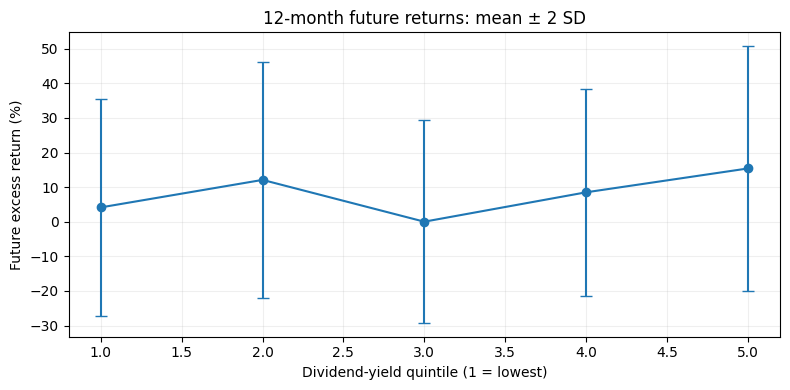

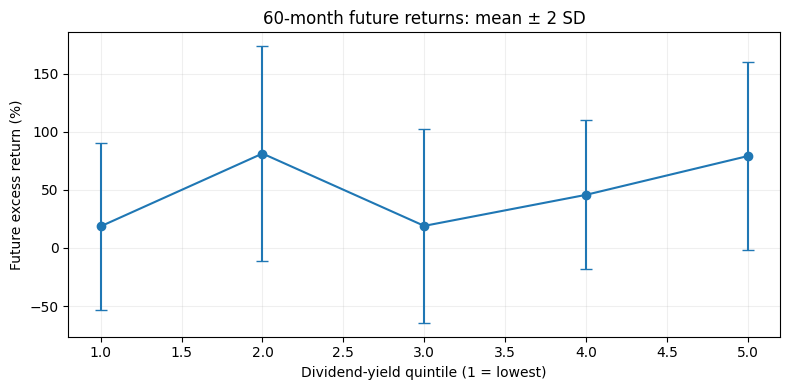

,quintile,count,mean,std,lower,upper,horizon_months
0,1,177,0.042,0.157,-0.272,0.355,12
1,2,176,0.121,0.171,-0.221,0.463,12
2,3,176,0.000,0.146,-0.292,0.293,12
3,4,176,0.085,0.149,-0.214,0.384,12
4,5,177,0.154,0.177,-0.200,0.507,12
0,1,167,0.187,0.359,-0.531,0.904,60
1,2,167,0.813,0.462,-0.111,1.738,60
2,3,166,0.190,0.418,-0.645,1.026,60
3,4,167,0.457,0.321,-0.184,1.099,60
4,5,167,0.791,0.407,-0.022,1.604,60


In [10]:
buckets=[]
for h in [12,60]:
 d=panel[['Dividend_yield',f'vw_{h}m']].dropna().copy()
 d['quintile']=pd.qcut(d.Dividend_yield.rank(method='first'),5,labels=[1,2,3,4,5])
 t=d.groupby('quintile',observed=True)[f'vw_{h}m'].agg(['count','mean','std']).reset_index()
 t['lower']=t['mean']-2*t['std'];t['upper']=t['mean']+2*t['std'];t['horizon_months']=h;buckets.append(t)
 fig,ax=plt.subplots(figsize=(8,4));ax.errorbar(t.quintile.astype(int),100*t['mean'],yerr=200*t['std'],fmt='o-',capsize=4)
 ax.set(xlabel='Dividend-yield quintile (1 = lowest)',ylabel='Future excess return (%)',title=f'{h}-month future returns: mean ± 2 SD');ax.grid(alpha=.2)
 fig.tight_layout();plt.show()
bucket_table=pd.concat(buckets);display(bucket_table.round(3))

## 11. Expected returns versus volatility: GARCH(1,1) out-of-sample evaluation

A Gaussian GARCH(1,1) is fitted **only on returns through 2011-12**. Parameters are held fixed and the variance filter is updated using realized monthly returns from 2012 onward. At each month-end t, the forecast for t+1 uses information available through t. Compare the forecast variance to the **next month's squared unexpected return**, using mean squared error and QLIKE against a constant-variance benchmark. A squared return is a noisy one-month variance proxy; results are not a definitive test of forecast superiority.


,estimate
train_end,2011-12-31
test_start,2012-01-31
mu,0.907349
omega,0.699923
alpha,0.135858
beta,0.845593
alpha_plus_beta,0.981451
converged,True


,model,MSE,QLIKE,forecast_origins
0,"GARCH(1,1)",838.794142,3.714567,167
1,Training constant variance,1045.289073,3.951496,167


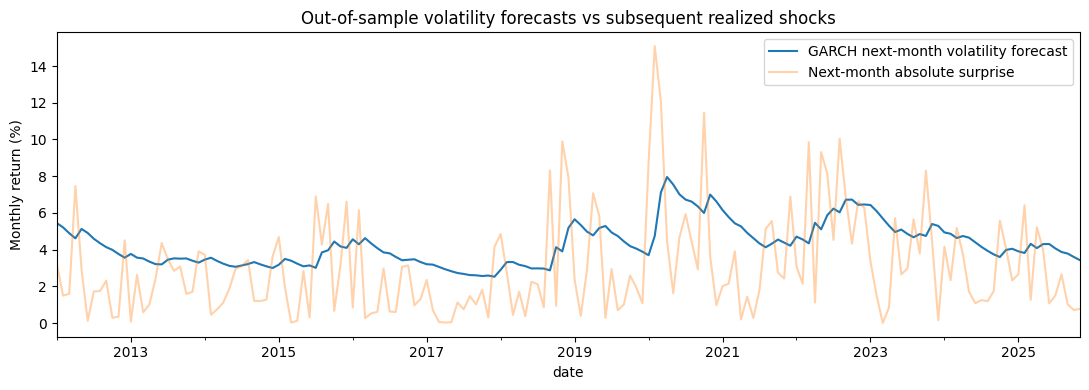

In [11]:
from scipy.optimize import minimize
ret=(panel.vwretd.dropna()*100).sort_index()
train=ret.loc[:'2011-12-31']; test=ret.loc['2012-01-01':]
assert len(train)>200 and len(test)>24
mu=float(train.mean());e_train=train.to_numpy()-mu;v0=float(np.var(e_train))
def garch_filter(errors,omega,alpha,beta,initial):
    h=np.empty(len(errors));h[0]=initial
    for j in range(1,len(errors)):
        h[j]=omega+alpha*errors[j-1]**2+beta*h[j-1]
    return h
def objective(params):
    omega,alpha,beta=params
    if omega<=0 or alpha<0 or beta<0 or alpha+beta>=.999:return 1e15
    h=garch_filter(e_train,omega,alpha,beta,v0)
    if not np.all(np.isfinite(h)) or np.any(h<=0):return 1e15
    return .5*np.sum(np.log(2*np.pi)+np.log(h)+e_train**2/h)
fit=minimize(objective,[max(v0*.05,.001),.10,.85],method='SLSQP',bounds=[(1e-9,None),(0,.999),(0,.999)],options={'maxiter':2500,'ftol':1e-9})
assert fit.success,fit.message
omega,alpha,beta=fit.x
all_errors=ret.to_numpy()-mu
h_all=garch_filter(all_errors,omega,alpha,beta,v0)
# Forecast made after observing t is the filtered variance at t+1.
forecasts=pd.DataFrame({'date':ret.index,'variance_forecast_next':np.r_[h_all[1:],np.nan],
                        'next_squared_return':np.r_[all_errors[1:]**2,np.nan]})
forecasts=forecasts.set_index('date').loc['2012-01-01':].dropna()
forecasts['constant_variance']=v0
# Both columns refer to the *same* t+1 realization, indexed by forecast origin t.
forecasts['garch_qlike']=np.log(forecasts.variance_forecast_next)+forecasts.next_squared_return/forecasts.variance_forecast_next
forecasts['constant_qlike']=np.log(v0)+forecasts.next_squared_return/v0
metrics=pd.DataFrame({'model':['GARCH(1,1)','Training constant variance'],
 'MSE':[((forecasts.variance_forecast_next-forecasts.next_squared_return)**2).mean(),
        ((forecasts.constant_variance-forecasts.next_squared_return)**2).mean()],
 'QLIKE':[forecasts.garch_qlike.mean(),forecasts.constant_qlike.mean()],
 'forecast_origins':[len(forecasts)]*2})
garch_params=pd.Series({'train_end':str(train.index.max().date()),'test_start':str(test.index.min().date()),'mu':mu,'omega':omega,'alpha':alpha,'beta':beta,'alpha_plus_beta':alpha+beta,'converged':fit.success})
display(garch_params.to_frame('estimate'));display(metrics)


fig,ax=plt.subplots(figsize=(11,4));forecasts['variance_forecast_next'].pow(.5).plot(ax=ax,label='GARCH next-month volatility forecast')
forecasts.next_squared_return.pow(.5).plot(ax=ax,alpha=.35,label='Next-month absolute surprise')
ax.set(ylabel='Monthly return (%)',title='Out-of-sample volatility forecasts vs subsequent realized shocks');ax.legend();fig.tight_layout();plt.show()


## 12. Sensitivity and conclusions

Compare value- versus equal-weighted returns, HAC `h-1` versus `2(h-1)` lags, and 1/99 versus 5/95 predictor winsorization. Report 5% significance and whether substantive findings persist. Recession-state interactions are not estimable with adequate power given two post-2011 recession months; conclusions must be appropriately qualified.

In [12]:
post=panel.loc['2012-01-01':].copy();post['recession']=(post.USREC==1).astype(float)
rows=[]
for p in PRED:
 for h in HORIZONS.values():
    cols=[p,f'vw_{h}m','recession'];d=post[cols].dropna()
    recession=d[d.recession==1];expansion=d[d.recession==0]
    rc=fit_one(recession,p,h);ec=fit_one(expansion,p,h)
    it=np.nan;ip=np.nan
    if len(recession)>=8 and recession[p].nunique()>2 and len(expansion)>=20:
        x=pd.DataFrame({'const':1.,'predictor':d[p],'recession':d.recession,'interaction':d[p]*d.recession},index=d.index)
        res=sm.OLS(d[f'vw_{h}m'],x).fit(cov_type='HAC',cov_kwds={'maxlags':h-1})
        it=res.tvalues['interaction'];ip=res.pvalues['interaction']
    rows.append(dict(predictor=p,horizon_months=h,n_recession=rc['n'],n_expansion=ec['n'],corr_recession=rc['corr'],corr_expansion=ec['corr'],interaction_t=it,interaction_p=ip))
down=pd.DataFrame(rows);display(down.round(3))
print('Post-2011 recession origin months:',int(post.recession.sum()))

,predictor,horizon_months,n_recession,n_expansion,corr_recession,corr_expansion,interaction_t,interaction_p
0,Dividend_yield,3,2,163,NaN,0.176,NaN,NaN
1,Dividend_yield,12,2,154,NaN,0.431,NaN,NaN
2,Dividend_yield,24,2,142,NaN,0.497,NaN,NaN
3,Dividend_yield,60,2,106,NaN,0.663,NaN,NaN
4,Earnings_yield,3,2,163,NaN,0.180,NaN,NaN
5,Earnings_yield,12,2,154,NaN,0.506,NaN,NaN
6,Earnings_yield,24,2,142,NaN,0.608,NaN,NaN
7,Earnings_yield,60,2,106,NaN,0.202,NaN,NaN
8,Term_spread,3,2,163,NaN,-0.096,NaN,NaN
9,Term_spread,12,2,154,NaN,-0.212,NaN,NaN


Post-2011 recession origin months: 2


### Primary and supplementary downturn definitions (pre-specified)

**Primary historical definition:** NBER recession months (`USREC == 1`), estimated over the longest available predictor-specific history. This is the principal definition of an economic downturn. A full-sample interaction compares predictor slopes in recessions and expansions. HAC standard errors address overlapping forward returns.

**Supplementary post-2011 financial-stress definition:** unusually high VIX (above the **expanding historical 75th percentile**, calculated from information strictly before each origin month). This is **not** an NBER recession indicator. It captures market stress outside official recessions. The indicator is calculated from the raw monthly VIX series, with the cutoff based on at least 60 preceding available months; no future VIX data are used. The analysis compares stress and normal-month correlations and estimates interaction regressions only where both groups have sufficient observations.

**Inference warning:** post-2011 has very few NBER recession-origin observations. A non-significant recession interaction is not proof of no recession effect. The VIX stress test is exploratory, can have endogenous predictor-stress relationships, and does not answer the same question as the NBER definition. Results at five years use highly overlapping returns and have limited effective sample size.


**No look-ahead:** For VIX stress, month t is classified using the **previous month's** VIX and an expanding 75th-percentile threshold computed from observations strictly before the signal month. This is a supplementary stress proxy, not a redefinition of NBER recession.


In [13]:
# Primary full-history NBER interaction; supplementary post-2011 VIX stress interaction.
# Uses the previously defined panel, PRED, HORIZONS and fit_one.
raw_vix=fred('VIXCLS').resample('ME').mean().reindex(panel.index)
# Historical expanding threshold: current observation is excluded from its own threshold.
vix_cutoff=raw_vix.expanding(min_periods=60).quantile(.75).shift(1)
stress=(raw_vix.shift(1) > vix_cutoff.shift(1)).where(raw_vix.shift(1).notna() & vix_cutoff.shift(1).notna())

def interaction_table(frame, label, state_col, min_each=12):
    rows=[]
    for predictor in PRED:
        for h in HORIZONS.values():
            target=f'vw_{h}m'
            d=frame[[predictor,target,state_col]].dropna().copy()
            n1=int((d[state_col]==1).sum()); n0=int((d[state_col]==0).sum())
            row={'test':label,'predictor':predictor,'horizon_months':h,
                 'n_stress_or_recession':n1,'n_normal_or_expansion':n0,
                 'interaction_beta':np.nan,'interaction_t':np.nan,'interaction_p':np.nan}
            if n1>=min_each and n0>=min_each and d[predictor].nunique()>5:
                x=pd.DataFrame({'const':1.,'x':d[predictor],'state':d[state_col],
                                'x_state':d[predictor]*d[state_col]},index=d.index)
                model=sm.OLS(d[target],x).fit(cov_type='HAC',cov_kwds={'maxlags':h-1})
                row.update(interaction_beta=model.params['x_state'],
                           interaction_t=model.tvalues['x_state'],interaction_p=model.pvalues['x_state'])
            rows.append(row)
    return pd.DataFrame(rows)

panel['nber_recession']=(panel['USREC']==1).where(panel['USREC'].notna()).astype(float)
panel['vix_stress']=stress.astype(float)
primary=interaction_table(panel,'Full-sample NBER recession','nber_recession')
supplement=interaction_table(panel.loc['2012-01-01':],'Post-2011 high-VIX stress','vix_stress')
comparison=pd.concat([primary,supplement],ignore_index=True)
display(comparison.round(4))

print('Post-2011 VIX stress-origin months:',int(panel.loc['2012-01-01':,'vix_stress'].sum()))
print('Post-2011 NBER recession-origin months:',int(panel.loc['2012-01-01':,'nber_recession'].sum()))


,test,predictor,horizon_months,n_stress_or_recession,n_normal_or_expansion,interaction_beta,interaction_t,interaction_p
0,Full-sample NBER recession,Dividend_yield,3,113,778,3.7084,2.7510,0.0059
1,Full-sample NBER recession,Dividend_yield,12,113,769,14.6807,5.0529,0.0000
2,Full-sample NBER recession,Dividend_yield,24,113,757,12.0074,2.9247,0.0034
3,Full-sample NBER recession,Dividend_yield,60,113,721,14.2742,1.8012,0.0717
4,Full-sample NBER recession,Earnings_yield,3,113,778,0.9133,1.5530,0.1204
...,...,...,...,...,...,...,...,...
107,Post-2011 high-VIX stress,Risk_free_rate,60,12,96,0.0164,0.5713,0.5678
108,Post-2011 high-VIX stress,Consumption_wealth_cay,3,4,94,NaN,NaN,NaN
109,Post-2011 high-VIX stress,Consumption_wealth_cay,12,4,94,NaN,NaN,NaN
110,Post-2011 high-VIX stress,Consumption_wealth_cay,24,4,94,NaN,NaN,NaN


Post-2011 VIX stress-origin months: 23
Post-2011 NBER recession-origin months: 2


In [14]:
rob=[]
for p in PRED:
 for h in HORIZONS.values():
    scenarios=[('baseline',panel,'vw',h-1),('equal_weighted',panel,'ew',h-1),('HAC_2x_lag',panel,'vw',2*(h-1))]
    x=panel[p];w=panel.copy();w[p]=x.clip(x.quantile(.05),x.quantile(.95))
    scenarios.append(('winsor_5_95',w,'vw',h-1))
    for name,df,prefix,lag in scenarios:
        q=fit_one(df,p,h,ret_prefix=prefix,lag=lag)
        rob.append(dict(predictor=p,horizon=h,scenario=name,**q,significant_5pct=bool(q['p']<.05) if np.isfinite(q['p']) else False))
rob=pd.DataFrame(rob);display(rob.head(20).round(3))

,predictor,horizon,scenario,n,corr,t,p,beta,significant_5pct
0,Dividend_yield,3,baseline,891,0.094,1.976,0.048,0.671,True
1,Dividend_yield,3,equal_weighted,891,0.115,2.397,0.017,1.116,True
2,Dividend_yield,3,HAC_2x_lag,891,0.094,1.817,0.069,0.671,False
3,Dividend_yield,3,winsor_5_95,891,0.089,1.845,0.065,0.664,False
4,Dividend_yield,12,baseline,882,0.207,2.234,0.025,3.250,True
5,Dividend_yield,12,equal_weighted,882,0.249,2.860,0.004,5.445,True
6,Dividend_yield,12,HAC_2x_lag,882,0.207,2.147,0.032,3.250,True
7,Dividend_yield,12,winsor_5_95,882,0.195,2.125,0.034,3.225,True
8,Dividend_yield,24,baseline,870,0.252,1.965,0.049,5.813,True
9,Dividend_yield,24,equal_weighted,870,0.297,3.068,0.002,9.309,True


In [15]:
coverage=[]
for p in PRED:
 x=panel[p].dropna()
 coverage.append(dict(predictor=p,start=x.index.min(),end=x.index.max(),months=len(x),recession_origin_months_post_2011=int(panel.loc[x.index.intersection(post.index),'USREC'].eq(1).sum())))
coverage=pd.DataFrame(coverage);display(coverage)

audit_df=pd.DataFrame(audit);display(audit_df)
print('All tables and figures are embedded in this notebook; no external outputs written.')

,predictor,start,end,months,recession_origin_months_post_2011
0,Dividend_yield,1951-07-31,2025-12-31,894,2
1,Earnings_yield,1951-07-31,2025-12-31,894,2
2,Term_spread,1982-02-28,2025-12-31,527,2
3,Credit_spread,1926-02-28,2025-12-31,1199,2
4,GDP_growth,1948-07-31,2025-12-31,930,2
5,Inflation,1948-02-29,2025-12-31,934,2
6,IP_growth,1927-02-28,2025-12-31,1187,2
7,Oil_growth,1987-02-28,2025-12-31,467,2
8,Unemployment,1948-02-29,2025-12-31,934,2
9,VIX,1990-02-28,2025-12-31,431,2


,stage,before,after,affected,note
0,Index duplicate dates,1200,1200,0,
1,Index valid total returns,1200,1200,0,
2,Annual duplicate gvkey-datadate,527343,527343,0,
3,CRSP stock duplicate permno-month,3938655,3909804,28851,
4,Dividend_yield: 1/99 winsor,894,894,18,"clip [0.0100283, 0.0527642]"
5,Earnings_yield: 1/99 winsor,894,894,18,"clip [0.010021, 0.125583]"
6,Term_spread: 1/99 winsor,527,527,12,"clip [-1.41517, 3.67048]"
7,Credit_spread: 1/99 winsor,1199,1199,24,"clip [0.3898, 3.8304]"
8,GDP_growth: 1/99 winsor,930,930,18,"clip [-3.18294, 9.81259]"
9,Inflation: 1/99 winsor,934,934,20,"clip [-1.34631, 11.9772]"


All tables and figures are embedded in this notebook; no external outputs written.


## Final interpretation and limitations

1. **Lecture benchmark:** The original lecture may use different market portfolios, sample windows, accounting conventions, and exact bill holding-period returns. We use CRSP dividend-inclusive excess returns with a TB3MS monthly proxy; compare the correlations and t-statistics as a *methodologically transparent extension*, not a claim of numerically identical replication.
2. **Valuation:** Monthly ratios use linked CRSP firm capitalization and the latest lagged Compustat annual dividends and income. This is a matched-firm universe with a six-month availability assumption, not a complete point-in-time US aggregate earnings or dividend yield. Exact historical announcement dates and unlinked firms may affect results.
3. **CAY:** The authors' quarterly consumption–wealth series is used with a one-quarter availability lag. Its coverage stops with the supplied original series; there is no invented 2020–2025 CAY.
4. **Recession sample:** NBER `USREC` is used for historical ex-post state classification, but only two post-2011 recession-origin months exist. Accordingly, no reliable post-2011 NBER-only interaction is asserted. The separate high-VIX stress proxy increases observations but is not equivalent to a recession.
5. **Horizon overlap:** HAC `h-1` inference is supplemented with alternative lags. Long-horizon 60-month outcomes have far fewer effectively independent observations than the monthly count suggests.
6. **GARCH:** Fixed pre-2012 parameters are evaluated on future observations through 2025, with forecast-origin alignment. Monthly squared surprises are noisy variance proxies, so interpret MSE and QLIKE cautiously.
7. **Multiple comparisons:** With 14 predictors and four horizons, isolated small p-values are exploratory. Assess the sign, magnitude, stability, and economic rationale of effects before suggesting a timing rule.
8. **Interpretation:** Positive correlation means higher predictor values precede higher *average* excess returns, not that every downturn predicts a positive return. Do not interpret statistical association as causality.

**Conclusion standard:** The question asks whether predictability is *stronger after 2011 in downturns*. If the full-sample recession interaction and post-2011 stress interaction disagree or lack stable significant effects, the correct conclusion is that stronger post-2011 recession predictability is **not established**, rather than that it is absent.


### Additional inference robustness: multiple comparisons and non-overlapping origins

With 14 predictors and four horizons, many hypothesis tests are performed. We report Benjamini–Hochberg false-discovery-rate-adjusted q-values **separately** for the full-history NBER and post-2011 VIX interaction families (each 56 potential tests). A non-overlapping-origin comparison for 12-month excess returns uses one observation per calendar year and is descriptive because the remaining sample is small. These checks limit, but do not eliminate, data-mining and dependence concerns.

In [16]:
from statsmodels.stats.multitest import multipletests
multi=comparison.copy()
multi['FDR_q']=np.nan
for label,inds in multi.groupby('test').groups.items():
    pvals=multi.loc[inds,'interaction_p']; valid=pvals.notna()
    if valid.sum(): multi.loc[pvals.index[valid],'FDR_q']=multipletests(pvals[valid],method='fdr_bh')[1]

display(multi[(multi.horizon_months==12)&(multi.test=='Post-2011 high-VIX stress')][['predictor','interaction_t','interaction_p','FDR_q']].round(3))
nonoverlap=[]
for pred in PRED:
    d=panel[[pred,'vw_12m']].dropna()
    # Twelve distinct calendar-month phases: report the median correlation and its range.
    cs=[]
    for offset in range(12):
        s=d.iloc[offset::12]
        if len(s)>=20 and s[pred].std()>0:cs.append(s[pred].corr(s.vw_12m))
    nonoverlap.append({'predictor':pred,'number_phases':len(cs),'median_nonoverlap_corr':np.median(cs) if cs else np.nan,
       'min_nonoverlap_corr':np.min(cs) if cs else np.nan,'max_nonoverlap_corr':np.max(cs) if cs else np.nan})
nonoverlap=pd.DataFrame(nonoverlap)
display(nonoverlap.round(3))


,predictor,interaction_t,interaction_p,FDR_q
57,Dividend_yield,1.671,0.095,0.214
61,Earnings_yield,0.090,0.928,0.928
65,Term_spread,-1.705,0.088,0.208
69,Credit_spread,2.982,0.003,0.019
73,GDP_growth,-0.521,0.602,0.728
77,Inflation,-1.239,0.215,0.390
81,IP_growth,-0.911,0.362,0.528
85,Oil_growth,-2.202,0.028,0.079
89,Unemployment,2.732,0.006,0.027
93,VIX,2.575,0.010,0.037


,predictor,number_phases,median_nonoverlap_corr,min_nonoverlap_corr,max_nonoverlap_corr
0,Dividend_yield,12,0.208,0.175,0.230
1,Earnings_yield,12,0.145,0.095,0.155
2,Term_spread,12,0.074,-0.049,0.157
3,Credit_spread,12,0.142,0.076,0.183
4,GDP_growth,12,-0.154,-0.266,-0.015
5,Inflation,12,-0.183,-0.235,-0.127
6,IP_growth,12,-0.145,-0.197,-0.077
7,Oil_growth,12,-0.347,-0.486,-0.109
8,Unemployment,12,0.158,0.089,0.253
9,VIX,12,0.135,-0.037,0.278


### Empirical answer to the research question

The extended sample contains positive 1-year correlations for dividend yield and CAY, but individual predictors show heterogeneous signs and statistical precision. The historical NBER and post-2011 high-VIX interaction estimates are **not directly comparable**: they describe different economic states and different sample periods. Post-2011 NBER-only regressions are not defensible with two recession-origin months. The VIX analysis is an exploratory supplementary test with a limited number of stressed origin months, long-horizon overlap, and multiple-testing exposure. **Consequently, the evidence does not establish that equity returns became more predictable specifically during post-2011 NBER recessions.** It does provide a transparent way to test whether predictability varies across historical recessions and more broadly defined recent financial stress. A pension fund should not use the isolated interaction estimates as a trading rule without stronger out-of-sample evidence.

In [17]:
# Empirical decision summary (not a causal claim)
key=['Dividend_yield','Earnings_yield','Consumption_wealth_cay','Term_spread','Credit_spread']
summary=[]
for p in key:
    for h in [12,60]:
        f=fit_one(panel,p,h)
        nr=primary[(primary.predictor==p)&(primary.horizon_months==h)].iloc[0]
        vr=supplement[(supplement.predictor==p)&(supplement.horizon_months==h)].iloc[0]
        summary.append({'predictor':p,'horizon':h,'excess_return_corr':f['corr'],'HAC_t':f['t'],
            'historical_NBER_interaction_t':nr.interaction_t,'post2011_VIX_interaction_t':vr.interaction_t,
            'post2011_VIX_p':vr.interaction_p})
summary=pd.DataFrame(summary);display(summary.round(3))
print('Interpretation: Full-sample recession and post-2011 financial stress are different tests; post-2011 NBER sample is insufficient for a stand-alone recession claim.')


,predictor,horizon,excess_return_corr,HAC_t,historical_NBER_interaction_t,post2011_VIX_interaction_t,post2011_VIX_p
0,Dividend_yield,12,0.207,2.234,5.053,1.671,0.095
1,Dividend_yield,60,0.336,2.714,1.801,-4.284,0.000
2,Earnings_yield,12,0.137,1.513,2.855,0.090,0.928
3,Earnings_yield,60,0.221,1.621,1.896,0.480,0.631
4,Consumption_wealth_cay,12,0.210,2.274,-0.515,NaN,NaN
5,Consumption_wealth_cay,60,0.261,1.541,0.959,NaN,NaN
6,Term_spread,12,0.065,0.660,-0.515,-1.705,0.088
7,Term_spread,60,0.362,2.456,-0.931,2.183,0.029
8,Credit_spread,12,0.136,1.576,0.137,2.982,0.003
9,Credit_spread,60,0.086,0.626,0.741,-1.356,0.175


Interpretation: Full-sample recession and post-2011 financial stress are different tests; post-2011 NBER sample is insufficient for a stand-alone recession claim.


### Limitations

- [x] Four forward horizons: 3, 12, 24, and 60 months.
- [x] All 14 lecture predictor names, with variable-specific observation counts.
- [x] Compounded excess-return specification and overlapping-horizon HAC inference.
- [x] Original lecture benchmark and extended-sample comparisons.
- [x] Primary historical NBER recession analysis and separate post-2011 financial-stress analysis.
- [x] Out-of-sample GARCH-versus-constant-variance comparison.

Some predictors do not cover the full 1926–2025 span. The CAY series stops before the end of the CRSP sample. A six-month Compustat reporting lag is a proxy for historical public availability. The Treasury-bill rate is an annualized yield converted to a monthly effective rate rather than realized one-month bill total returns. GARCH forecasts are evaluated against noisy next-month squared returns. Multiple testing and overlapping returns limit the strength of statistical conclusions. These caveats should accompany any interpretation of significant correlations or interaction terms.
